# Manual alignment check

Was the first guess at alignment OK? We can take a closer look at the accelerometer and how it lines up with specified blocks.

Consider the mid pause, where participants are likely to change their behavior (moving, talking), and another shorter pause towards the end. Acceleration magnitude and derivative (jerk) should be informative.

In [1]:
import os

import matplotlib.pyplot as plt
import mne
import mne_bids
import mne_nirs
import numpy as np
import pandas as pd
from scipy.ndimage import uniform_filter1d
from scipy.signal import detrend

In [2]:
# Smoothing params and when second smaller pause comes
SMOOTH_SEC = 10.0           
SECONDARY_PAUSE_CONDITION = 'LowPL-HighWM' 

# BIDS params
task = 'lettersearch'
bids_root = 'data/lettersearch_BIDS'
datatype = 'nirs'
out_dir = 'data'

bids_folder  = mne_bids.BIDSPath(root=bids_root, datatype=datatype)
nirs_files   = bids_folder.match()
all_subjects = sorted({f.subject for f in nirs_files})
print(f'{len(all_subjects)} subjects: {all_subjects}')

16 subjects: ['P1', 'P10', 'P11', 'P12', 'P13', 'P14', 'P15', 'P17', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9']


## Check current alignment



── P1 ──
  main pause: 429.1–566.0 s (137.0 s)
  secondary pause: 758.2–770.3 s (12.1 s)


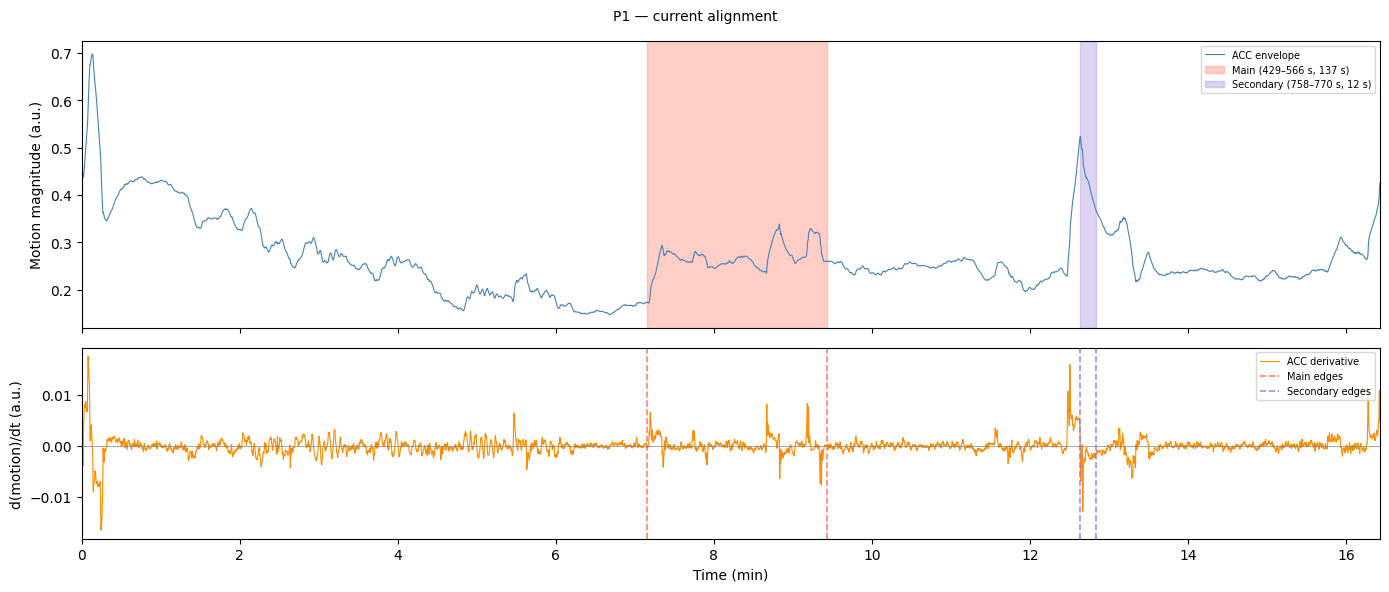


── P10 ──
  main pause: 455.0–590.4 s (135.4 s)
  secondary pause: 779.2–792.1 s (12.9 s)


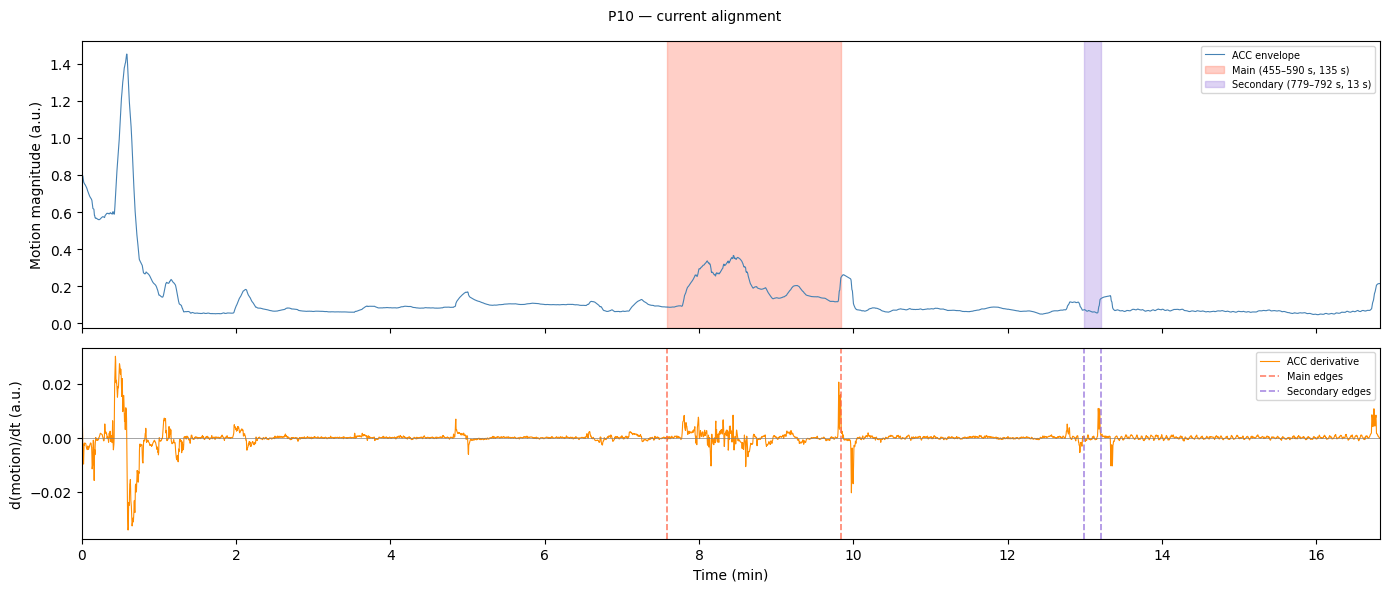


── P11 ──
  main pause: 420.8–557.6 s (136.8 s)
  secondary pause: 747.2–760.1 s (12.9 s)


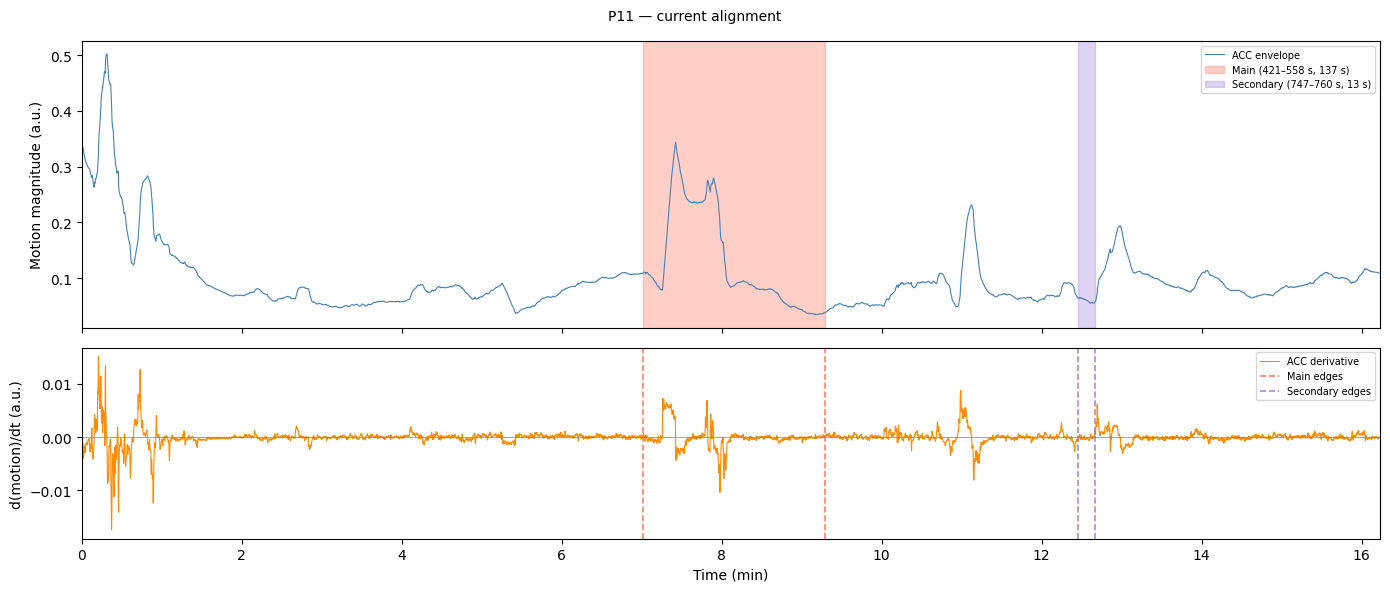


── P12 ──
  main pause: 433.6–573.5 s (139.9 s)
  secondary pause: 762.3–778.6 s (16.2 s)


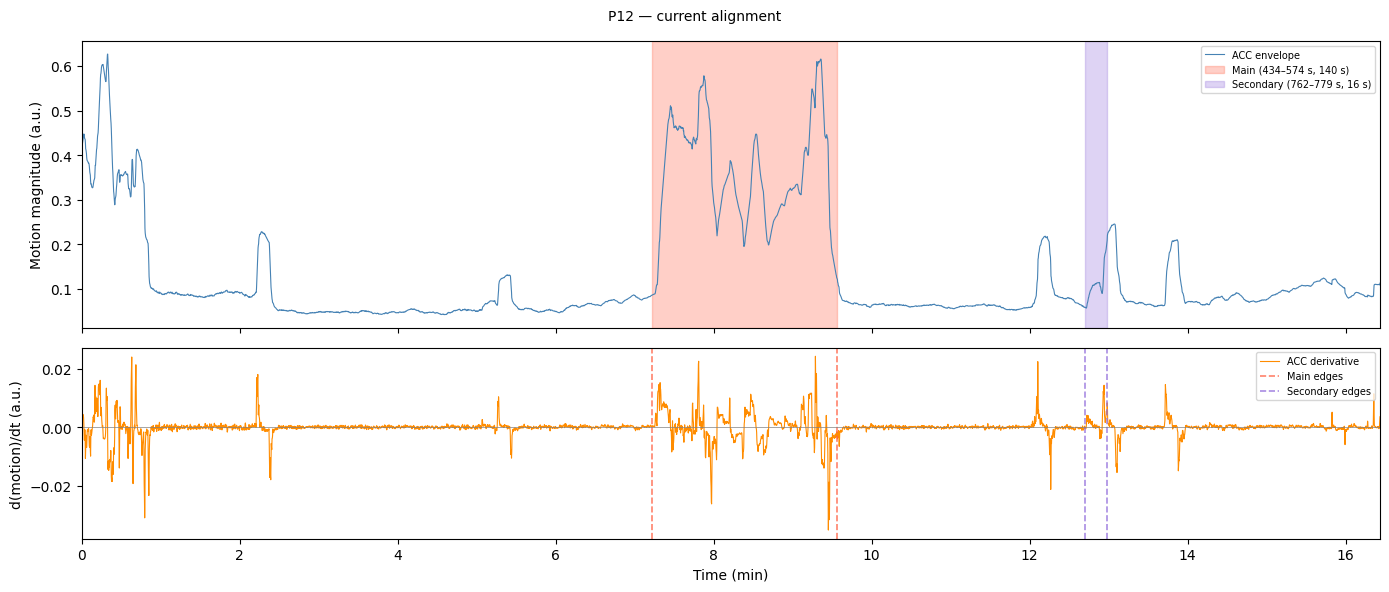


── P13 ──
  main pause: 436.6–586.7 s (150.1 s)
  secondary pause: 776.9–802.9 s (26.1 s)


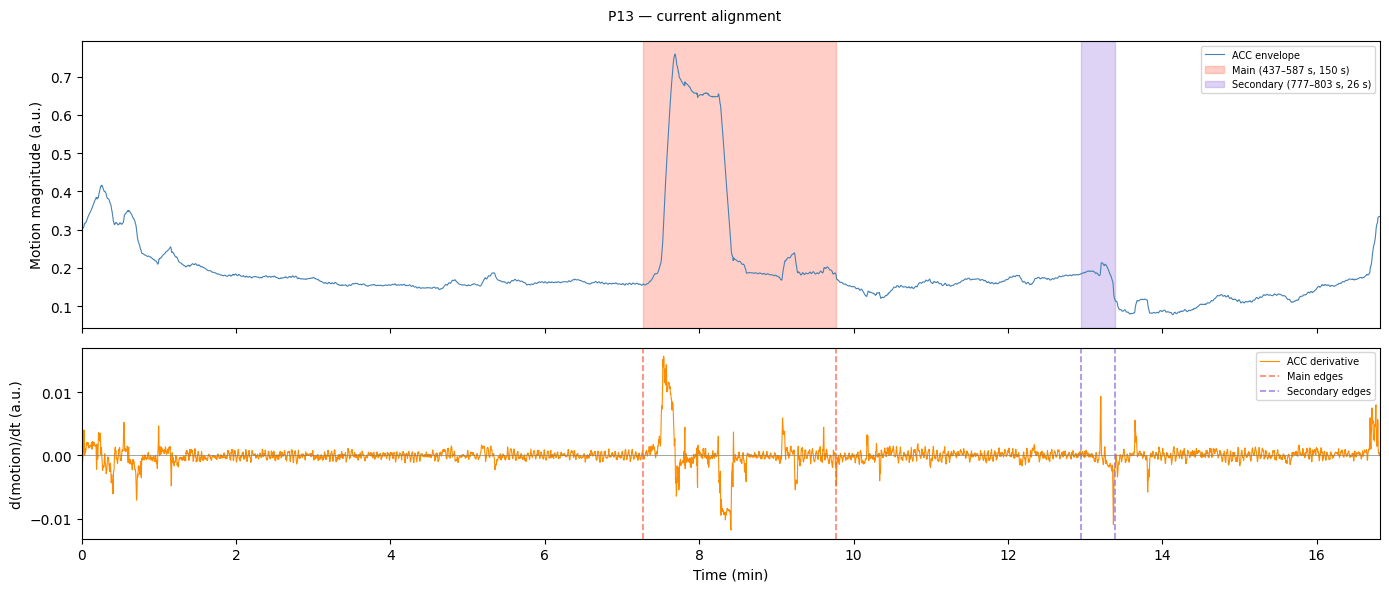


── P14 ──
  main pause: 429.7–563.9 s (134.2 s)
  secondary pause: 752.5–765.4 s (12.9 s)


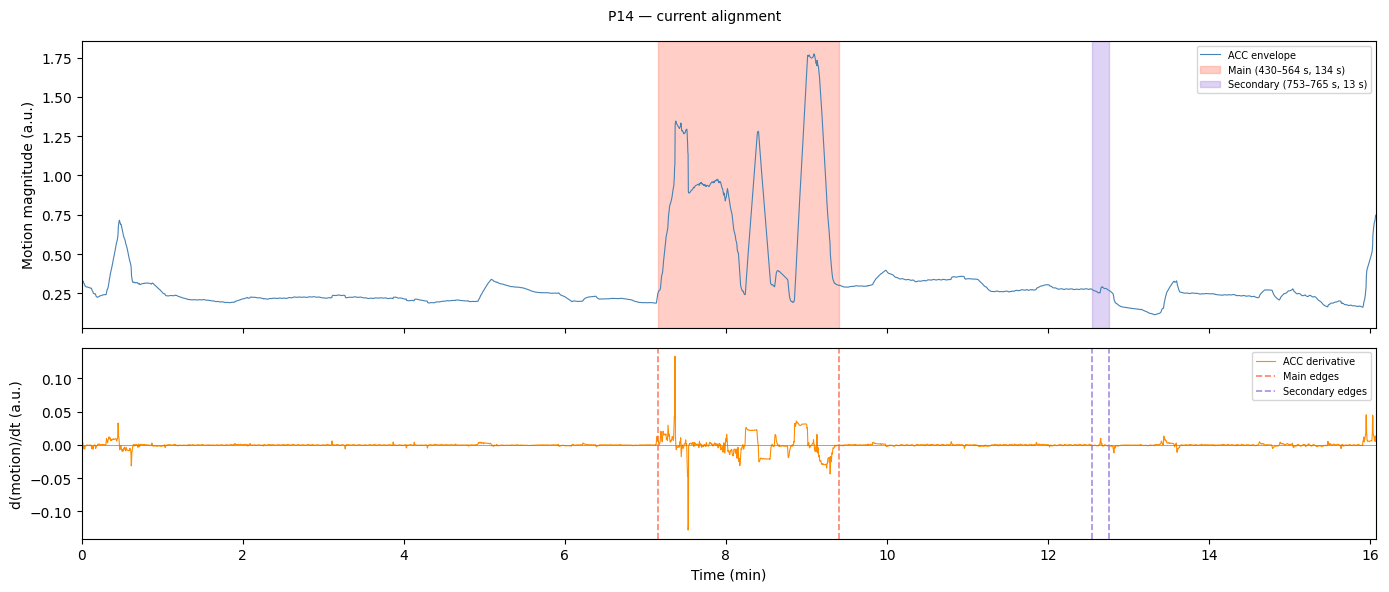


── P15 ──
  main pause: 402.9–535.8 s (132.8 s)
  secondary pause: 724.6–737.7 s (13.1 s)


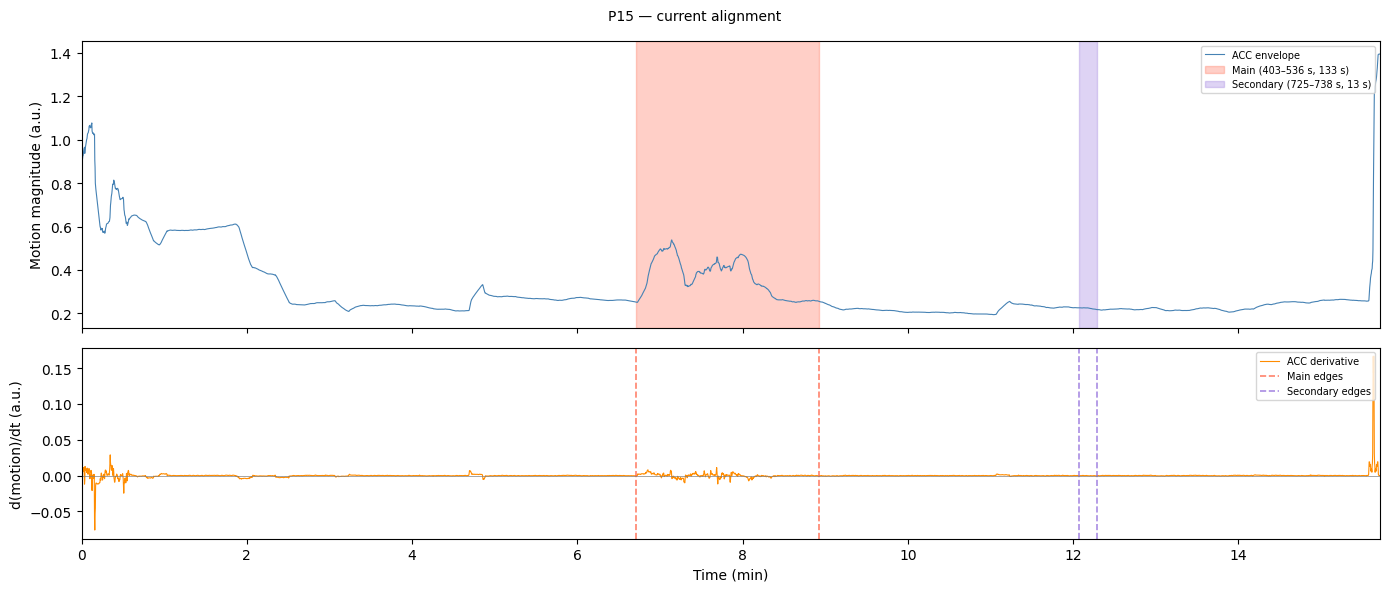


── P17 ──
  main pause: 412.6–544.4 s (131.8 s)
  secondary pause: 736.0–747.3 s (11.3 s)


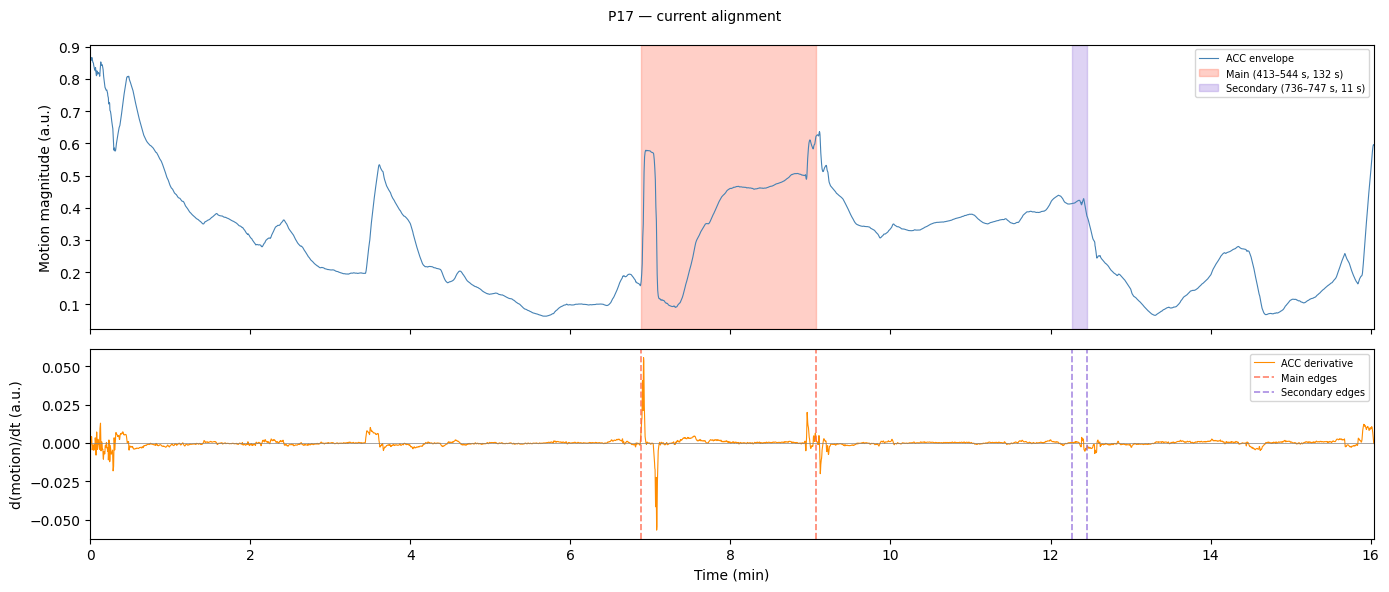


── P2 ──
  main pause: 416.5–555.4 s (138.9 s)
  secondary pause: 747.2–769.3 s (22.1 s)


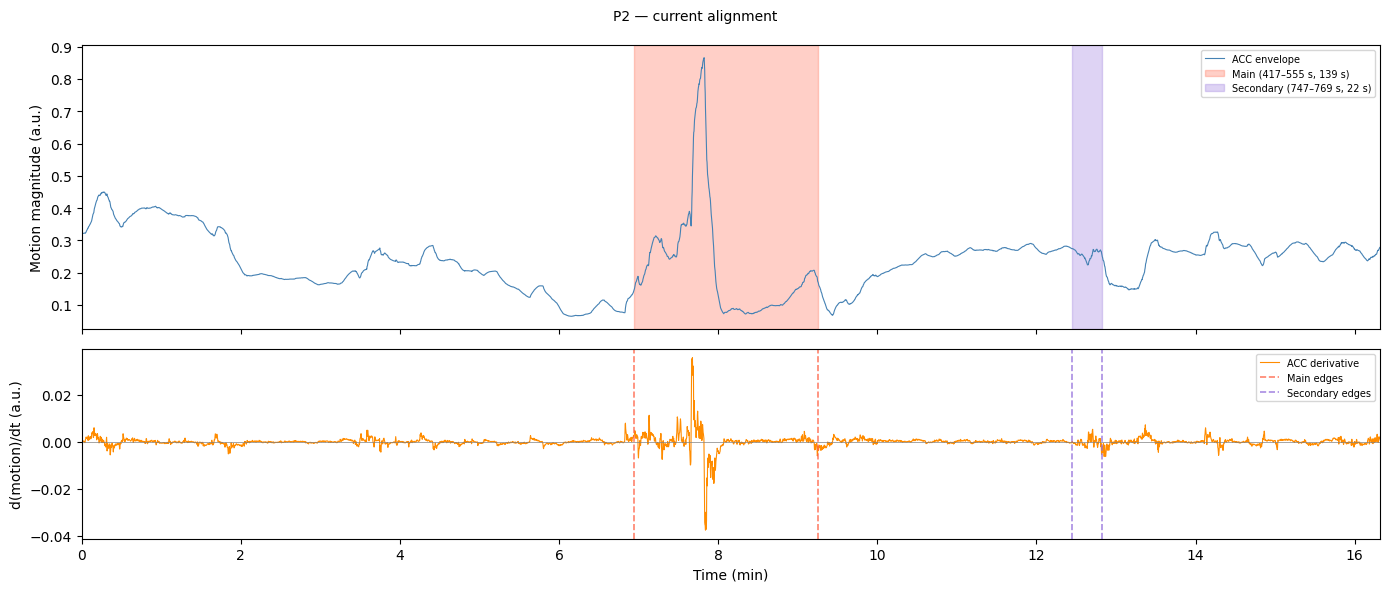


── P3 ──
  main pause: 403.9–547.9 s (144.0 s)
  secondary pause: 738.9–760.7 s (21.7 s)


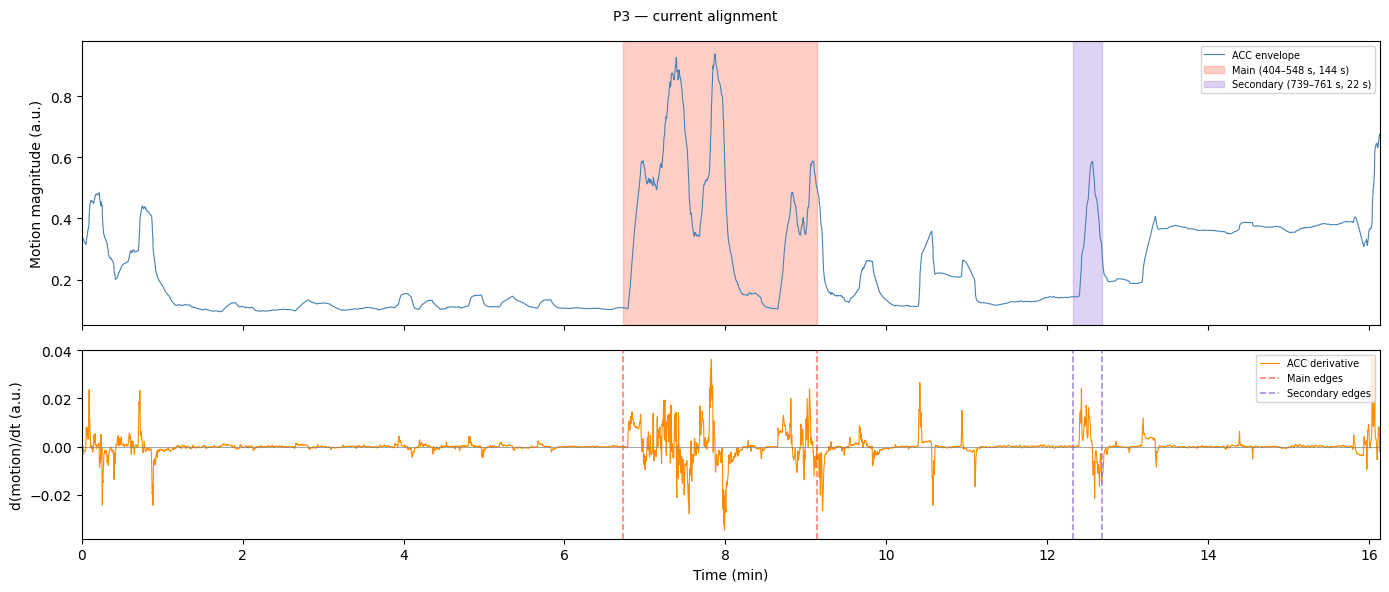


── P4 ──
  main pause: 414.3–565.6 s (151.3 s)
  secondary pause: 754.7–768.5 s (13.9 s)


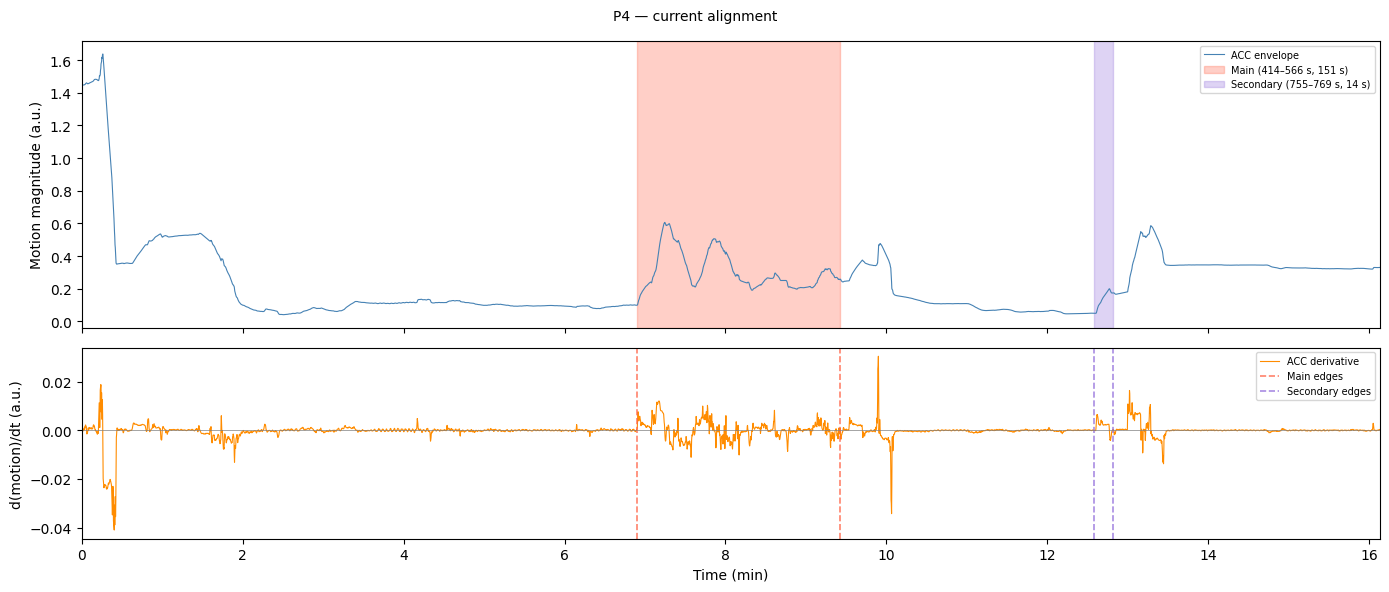


── P5 ──
  main pause: 407.8–547.7 s (139.9 s)
  secondary pause: 737.6–763.2 s (25.7 s)


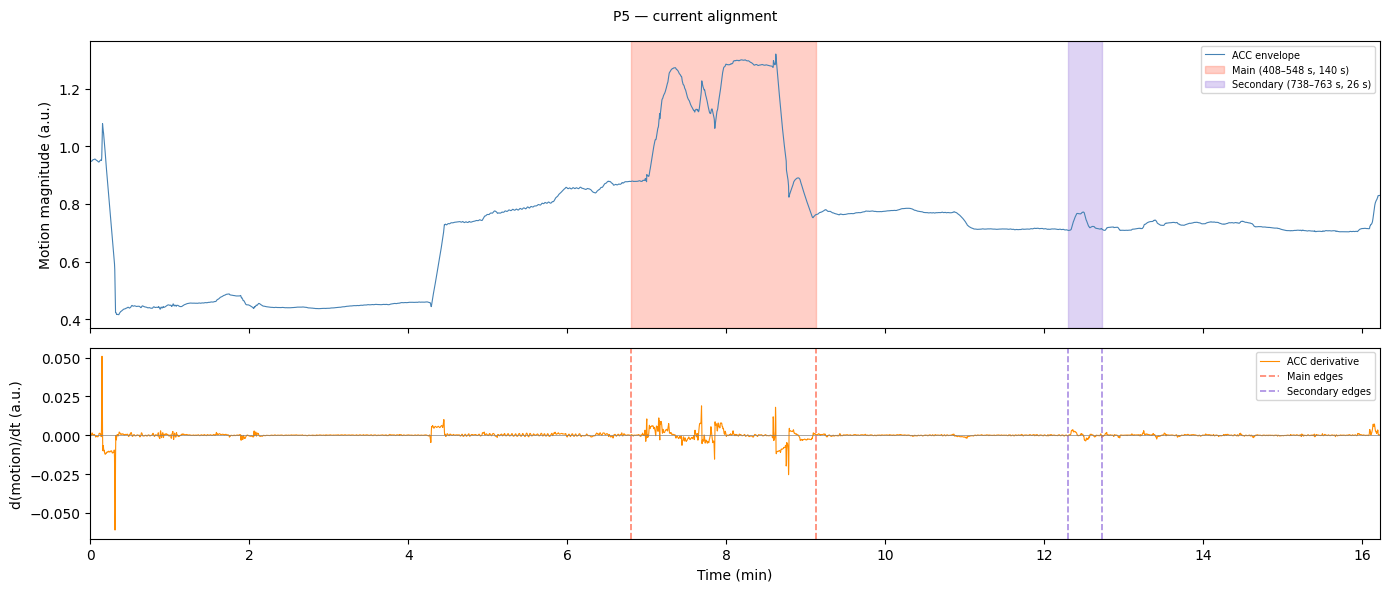


── P6 ──
  main pause: 435.6–574.9 s (139.3 s)
  secondary pause: 764.3–779.7 s (15.4 s)


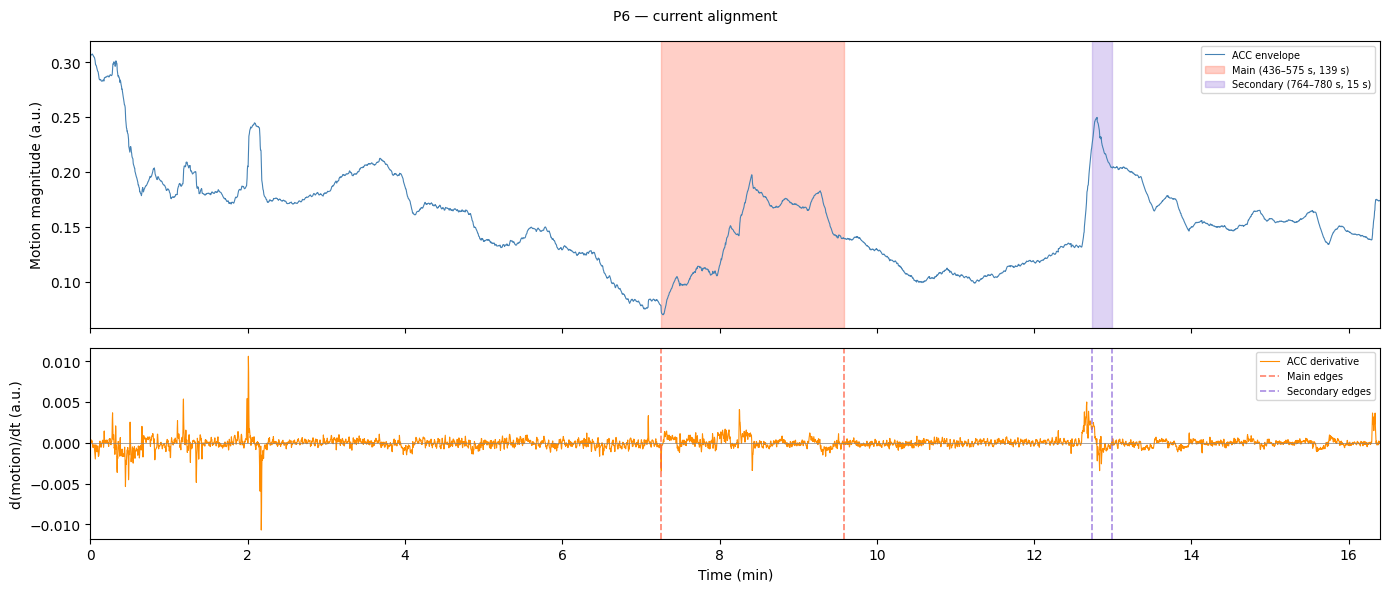


── P7 ──
  main pause: 425.9–570.4 s (144.4 s)
  secondary pause: 759.8–792.3 s (32.6 s)


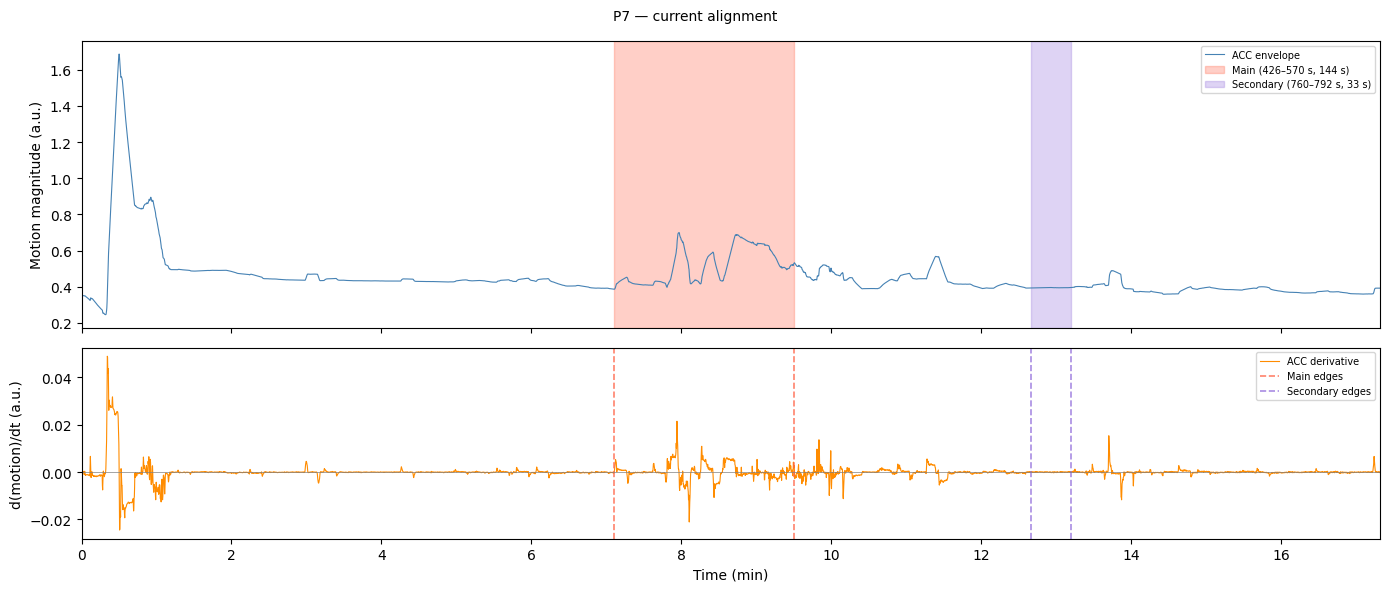


── P8 ──
  main pause: 462.3–602.4 s (140.1 s)
  secondary pause: 792.8–811.6 s (18.8 s)


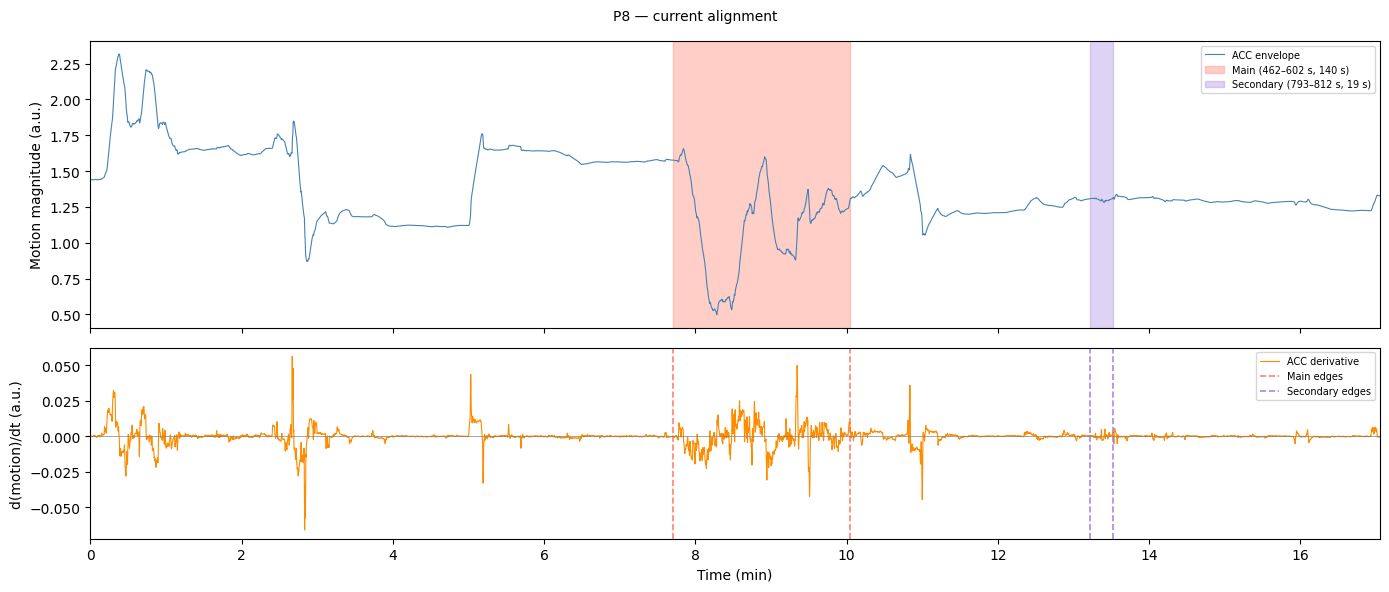


── P9 ──
  main pause: 437.3–585.7 s (148.4 s)
  secondary pause: 775.3–791.7 s (16.4 s)


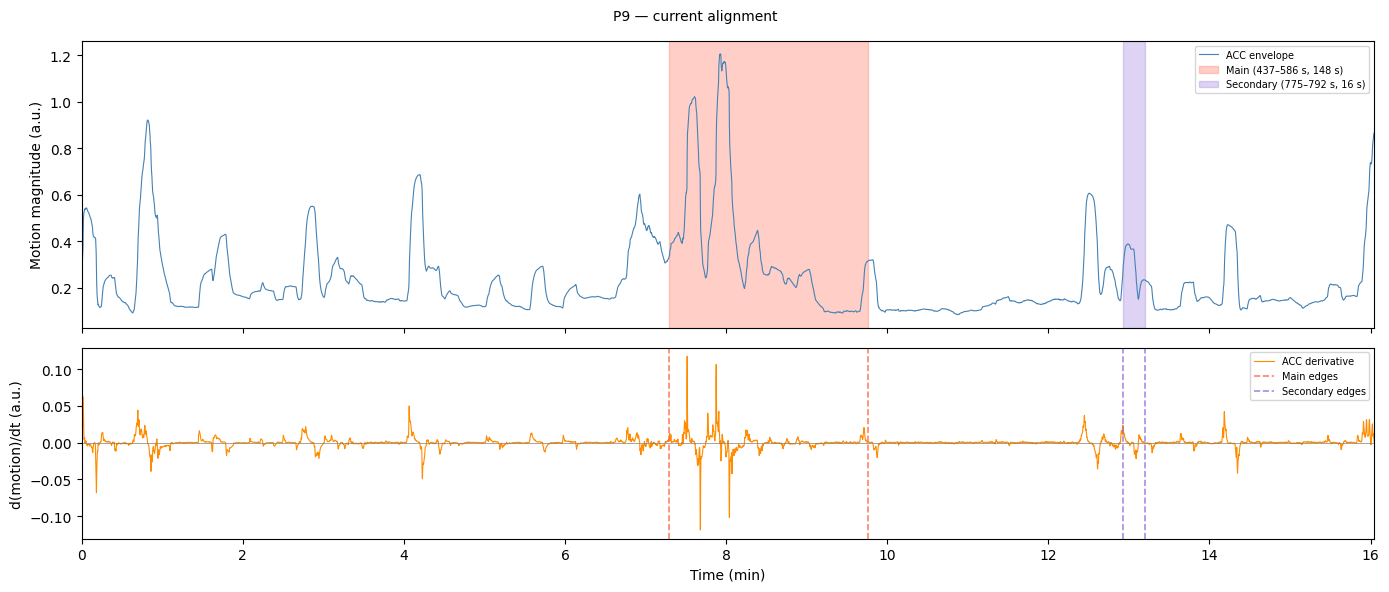


Done — 16/16 subjects loaded.


In [3]:
# For comparison later
subject_cache = {}

def _plot_rows(fig, axes, times, acc_smooth, acc_deriv, pause_info,
               pause_colors, offset=None):
    ax1, ax2 = axes
    t_min = times / 60

    ax1.plot(t_min, acc_smooth, color='steelblue', lw=0.8, label='ACC envelope')
    for p_start, p_stop, p_dur, p_label in pause_info:
        col = pause_colors[p_label]
        c_start = p_start + (offset or 0)
        c_stop  = p_stop  + (offset or 0)
        if offset is None:
            ax1.axvspan(p_start / 60, p_stop / 60, alpha=0.30, color=col,
                        label=f'{p_label.capitalize()} ({p_start:.0f}–{p_stop:.0f} s, {p_dur:.0f} s)')
        else:
            ax1.axvspan(p_start / 60, p_stop / 60, alpha=0.12, color=col,
                        label=f'{p_label.capitalize()} current ({p_start:.0f}–{p_stop:.0f} s)')
            ax1.axvspan(c_start / 60, c_stop / 60, alpha=0.30, color='mediumseagreen',
                        label=f'{p_label.capitalize()} adjusted ({c_start:.0f}–{c_stop:.0f} s)')
    ax1.set_ylabel('Motion magnitude (a.u.)')
    ax1.legend(fontsize=7, loc='upper right')
    ax1.set_xlim(t_min[0], t_min[-1])
    ax1.set_xticklabels([])

    ax2.plot(t_min, acc_deriv, color='darkorange', lw=0.8, label='ACC derivative')
    for p_start, p_stop, p_dur, p_label in pause_info:
        col = pause_colors[p_label]
        c_start = p_start + (offset or 0)
        c_stop  = p_stop  + (offset or 0)
        if offset is None:
            ax2.axvline(p_start / 60, color=col, lw=1.2, ls='--', alpha=0.8)
            ax2.axvline(p_stop  / 60, color=col, lw=1.2, ls='--', alpha=0.8,
                        label=f'{p_label.capitalize()} edges')
        else:
            ax2.axvline(p_start / 60, color=col,              lw=1.0, ls='--', alpha=0.40)
            ax2.axvline(p_stop  / 60, color=col,              lw=1.0, ls='--', alpha=0.40,
                        label=f'{p_label.capitalize()} current')
            ax2.axvline(c_start / 60, color='mediumseagreen', lw=1.2, ls='-',  alpha=0.85)
            ax2.axvline(c_stop  / 60, color='mediumseagreen', lw=1.2, ls='-',  alpha=0.85,
                        label=f'{p_label.capitalize()} adjusted')
    ax2.axhline(0, color='grey', lw=0.5)
    ax2.set_ylabel('d(motion)/dt (a.u.)')
    ax2.set_xlabel('Time (min)')
    ax2.legend(fontsize=7, loc='upper right')
    ax2.set_xlim(t_min[0], t_min[-1])

# Plot algnment for each subject
for subject in all_subjects:
    print(f'\n── {subject} ──', flush=True)

    bids_path = mne_bids.BIDSPath(
        subject=subject, task=task,
        suffix=datatype, datatype=datatype, root=bids_root,
    )

    raw   = mne_bids.read_raw_bids(bids_path=bids_path, verbose='ERROR')
    sfreq = raw.info['sfreq']
    times = raw.times
    n     = len(times)

    aux_df = mne_nirs.io.snirf.read_snirf_aux_data(raw.filenames[0], raw)
    acc = aux_df.to_numpy()

    acc_dyn    = detrend(acc, axis=0, type='constant')
    acc_rms    = np.sqrt(np.mean(acc_dyn ** 2, axis=1))
    smooth_n   = max(3, int(SMOOTH_SEC * sfreq))
    acc_smooth = uniform_filter1d(acc_rms, size=smooth_n)
    acc_deriv  = np.gradient(acc_smooth)

    ann  = raw.annotations

    onsets       = ann.onset
    durations    = ann.duration
    descriptions = ann.description
    ends         = onsets + durations
    gaps         = onsets[1:] - ends[:-1]

    main_pidx      = int(np.argmax(gaps))
    sec_candidates = np.where(descriptions[:-1] == SECONDARY_PAUSE_CONDITION)[0]
    sec_pidx = None
    if len(sec_candidates) > 0:
        candidate = int(sec_candidates[-1])
        if candidate != main_pidx:
            sec_pidx = candidate

    pause_indices    = [main_pidx] + ([sec_pidx] if sec_pidx is not None else [])
    pause_labels_map = {main_pidx: 'main'}
    if sec_pidx is not None:
        pause_labels_map[sec_pidx] = 'secondary'

    pause_info = []
    for pidx in pause_indices:
        p_start = float(ends[pidx])
        p_stop  = float(onsets[pidx + 1])
        p_label = pause_labels_map[pidx]
        pause_info.append((p_start, p_stop, p_stop - p_start, p_label))
        print(f'  {p_label} pause: {p_start:.1f}–{p_stop:.1f} s '
              f'({p_stop - p_start:.1f} s)', flush=True)

    subject_cache[subject] = dict(
        times=times, acc_smooth=acc_smooth, acc_deriv=acc_deriv,
        pause_info=pause_info,
    )

    fig, axes = plt.subplots(
        2, 1, figsize=(14, 6),
        gridspec_kw={'height_ratios': [3, 2]},
    )
    fig.suptitle(f'{subject} — current alignment', fontsize=10)
    pause_colors = {'main': 'tomato', 'secondary': 'mediumpurple'}
    _plot_rows(fig, axes, times, acc_smooth, acc_deriv, pause_info,
               pause_colors, offset=None)
    plt.tight_layout()
    plt.show()

print(f'\nDone — {len(subject_cache)}/{len(all_subjects)} subjects loaded.')

## Manual offsets

We shift as needed to match both the main pause and secondary pause.

In [4]:
manual_offsets = {
    'P10':  13.0,
    'P11': 5.0,
    'P14': 2.0,
    'P15': 3.0,
    'P17': 0.0,
    'P5': 8.0,
    'P6': -7.0,
    'P7': 45,
    'P9': -5
}

# Fill in 0.0 for any subject not listed above
for subject in subject_cache:
    manual_offsets.setdefault(subject, 0.0)

print('Offsets (s):')
for subj, off in sorted(manual_offsets.items()):
    print(f'{subj}: {off:+.2f} s')

Offsets (s):
P1: +0.00 s
P10: +13.00 s
P11: +5.00 s
P12: +0.00 s
P13: +0.00 s
P14: +2.00 s
P15: +3.00 s
P17: +0.00 s
P2: +0.00 s
P3: +0.00 s
P4: +0.00 s
P5: +8.00 s
P6: -7.00 s
P7: +45.00 s
P8: +0.00 s
P9: -5.00 s


## Re-check with adjustments

Faded color = current (unadjusted) position.  
Green = position after applying the offset.

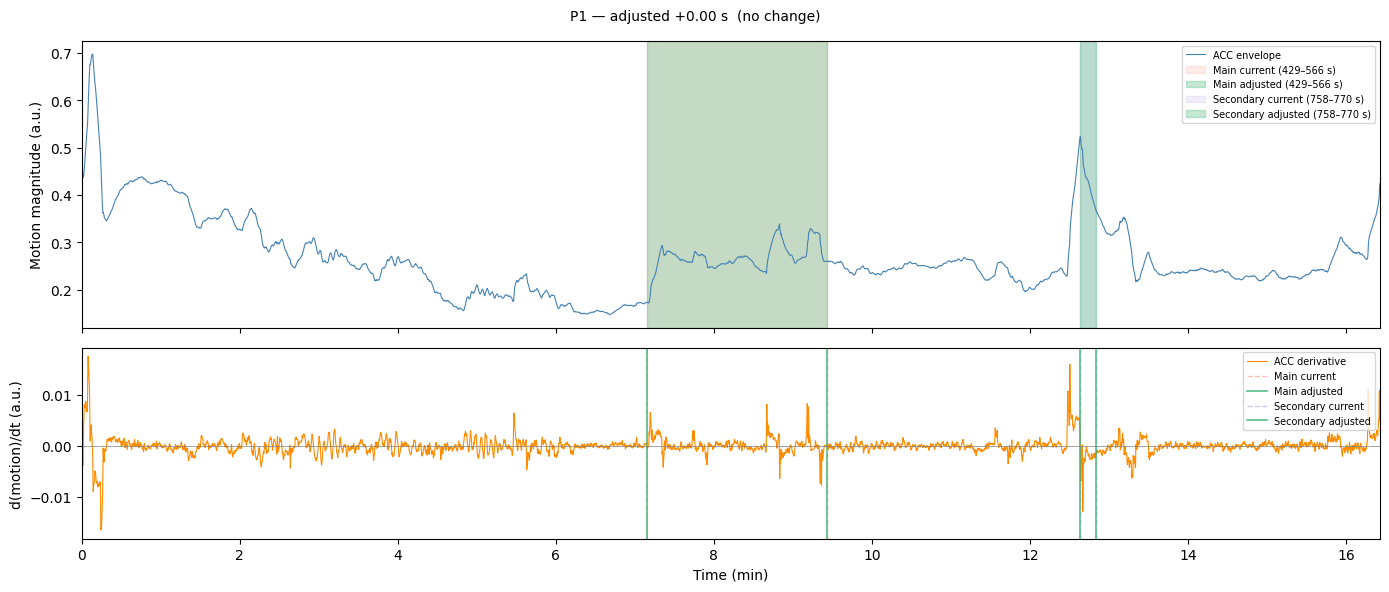

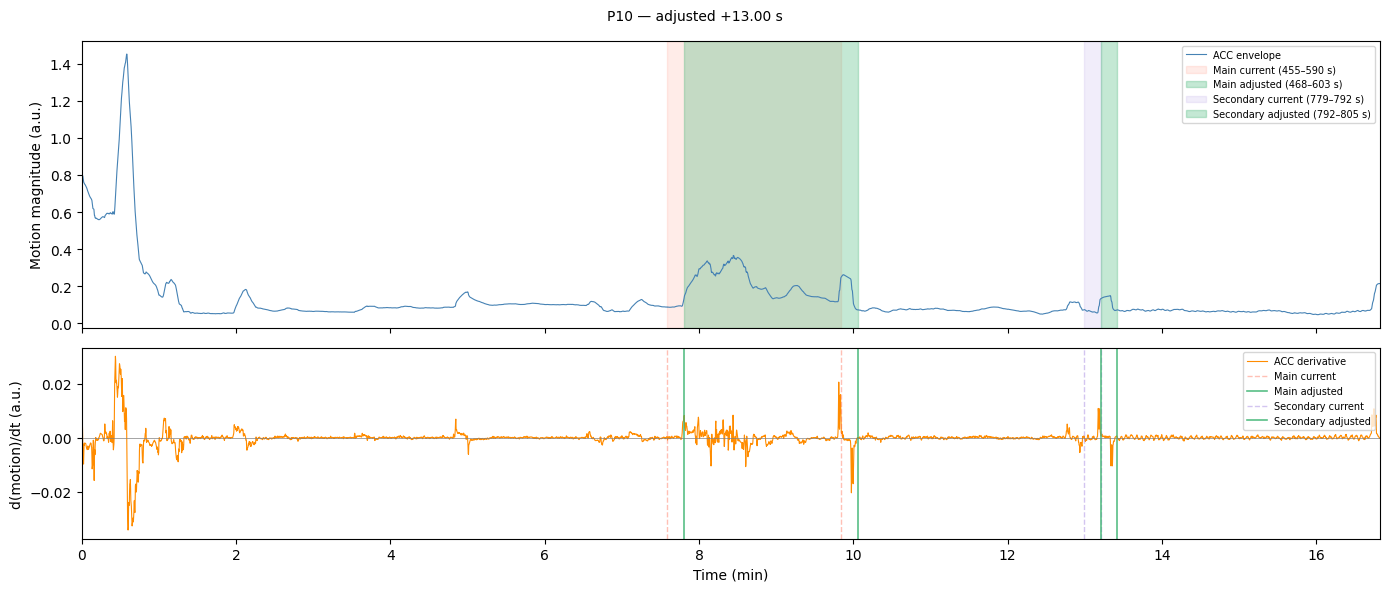

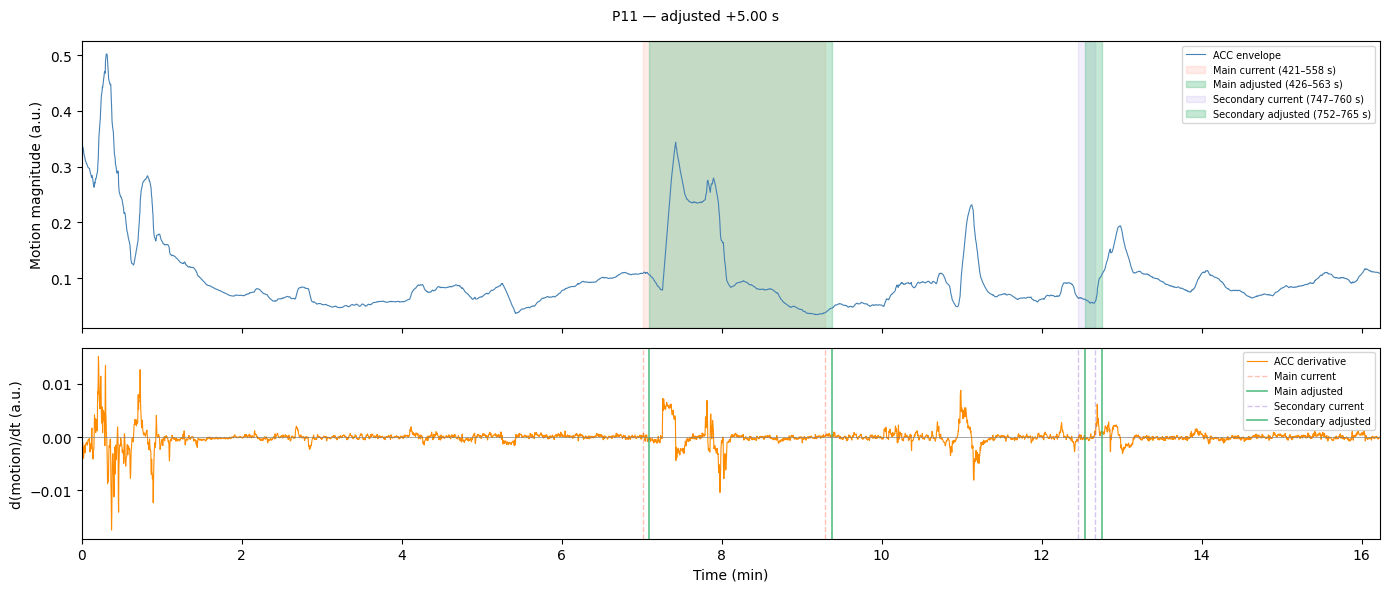

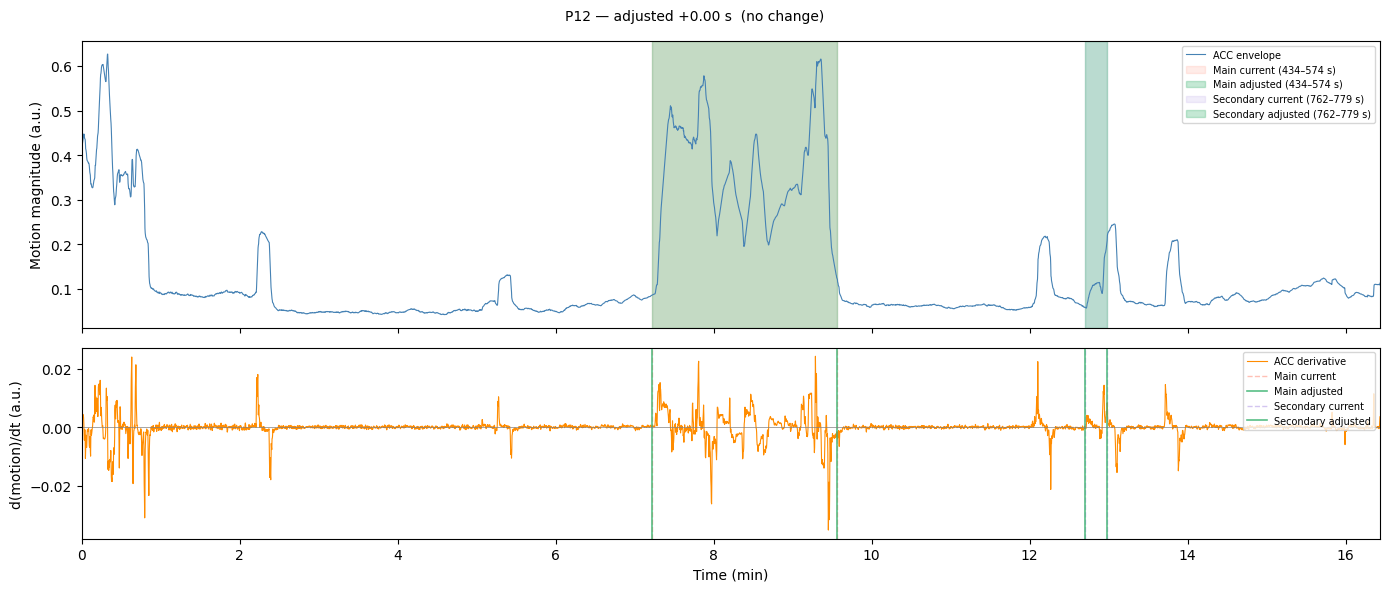

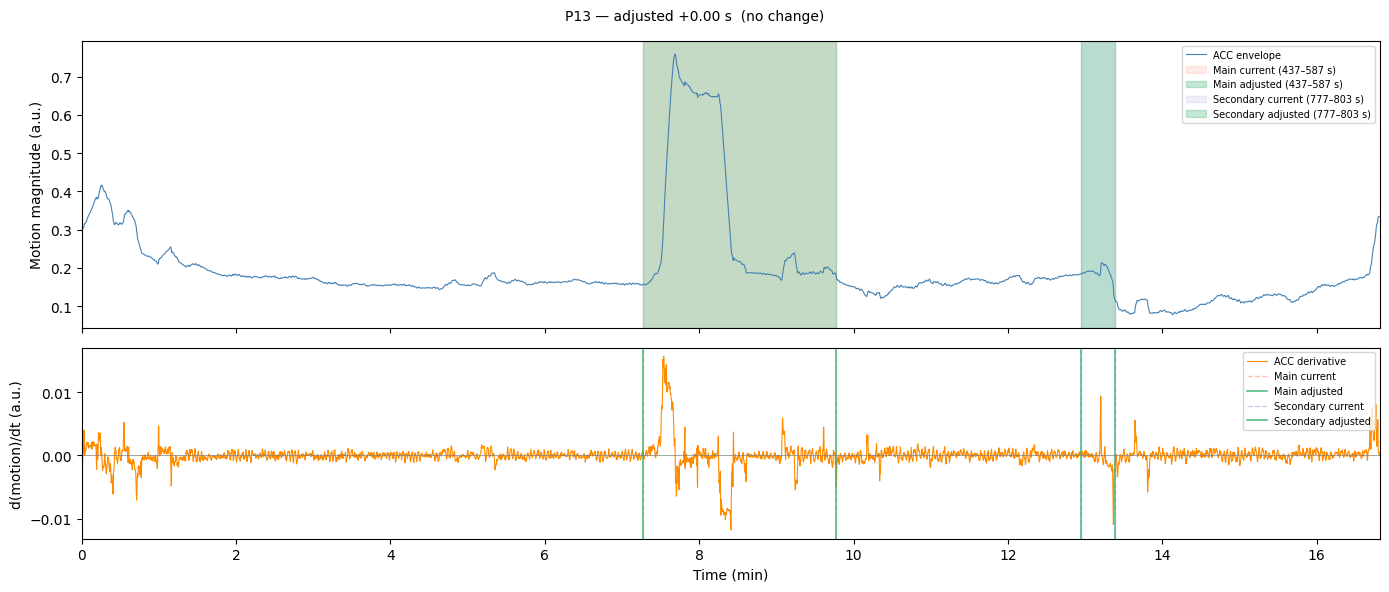

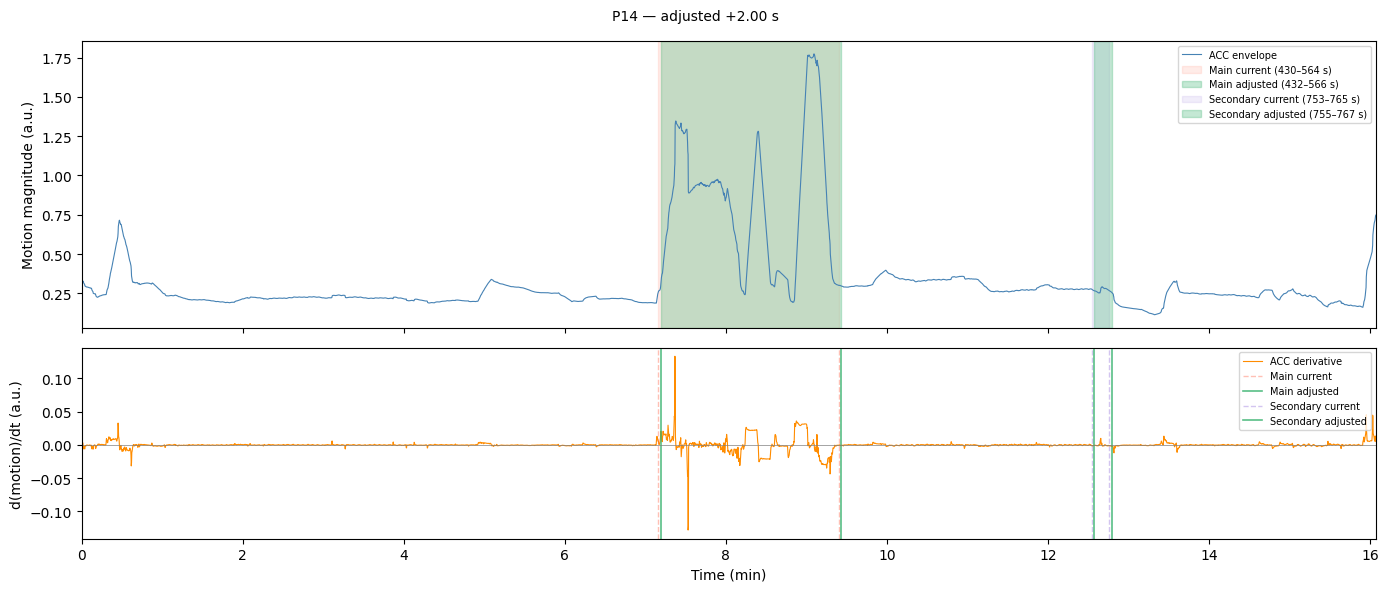

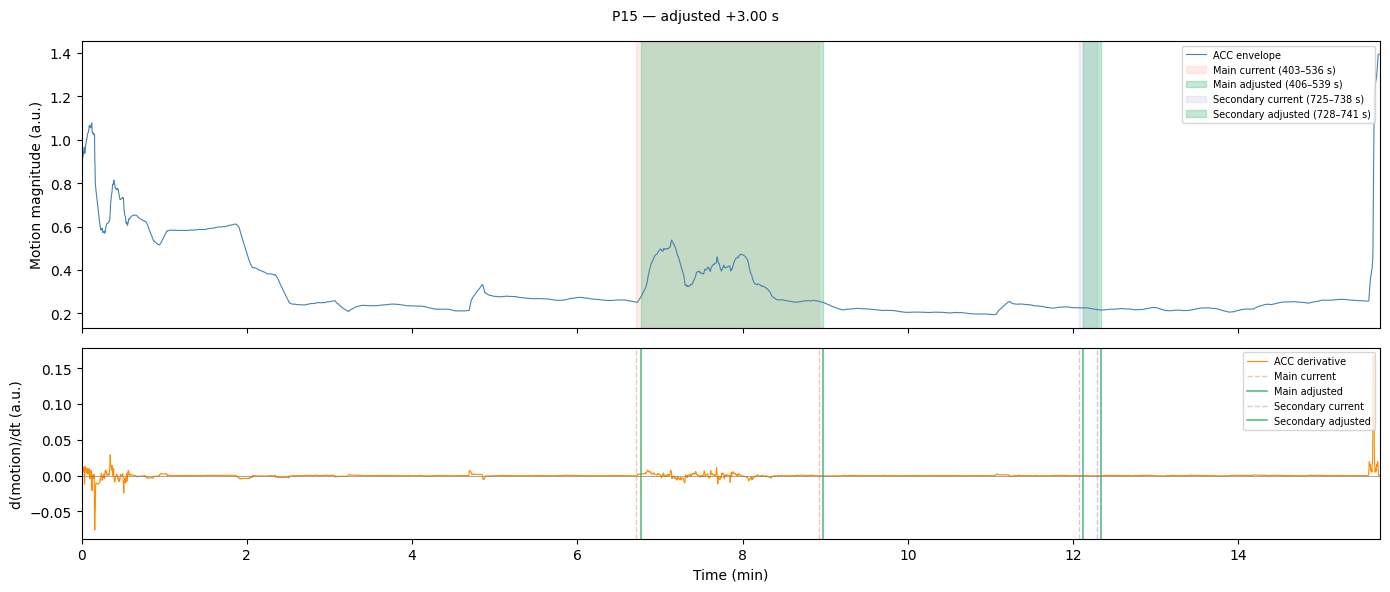

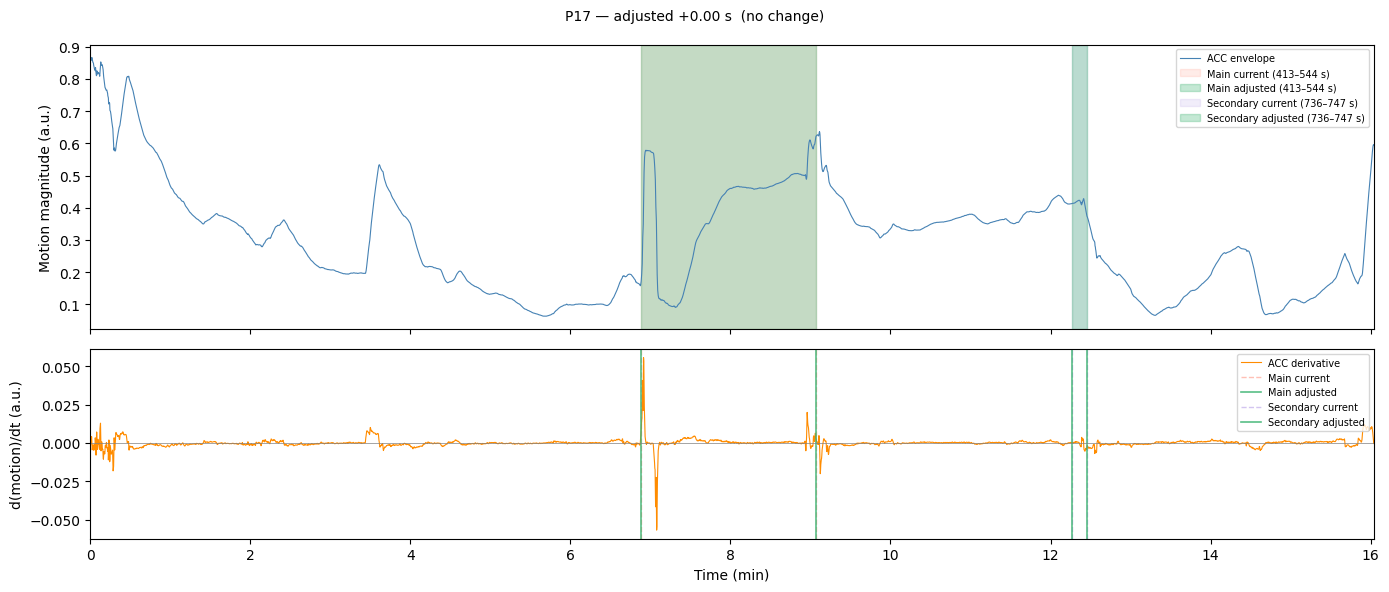

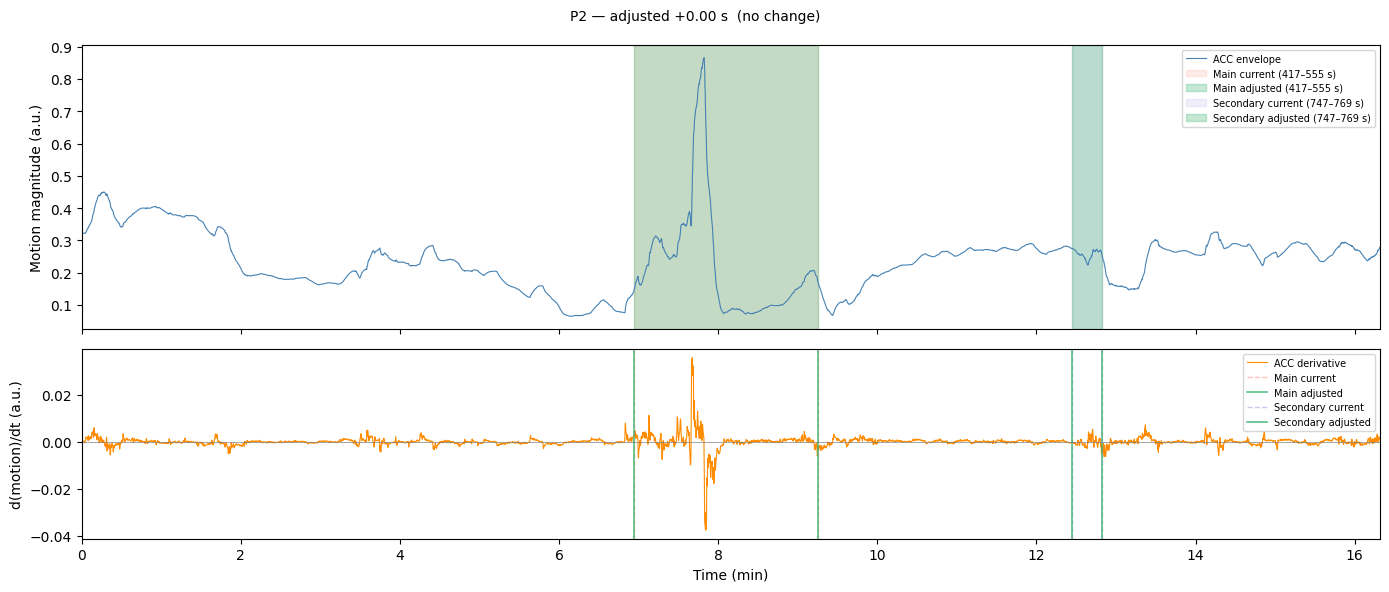

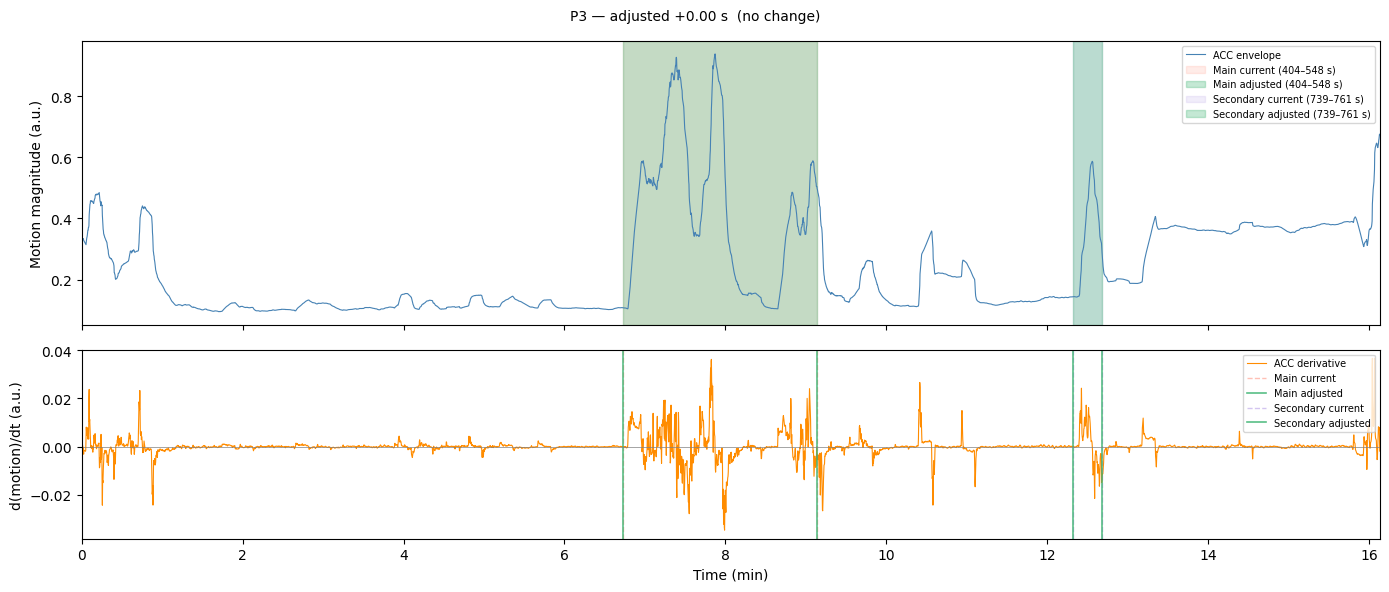

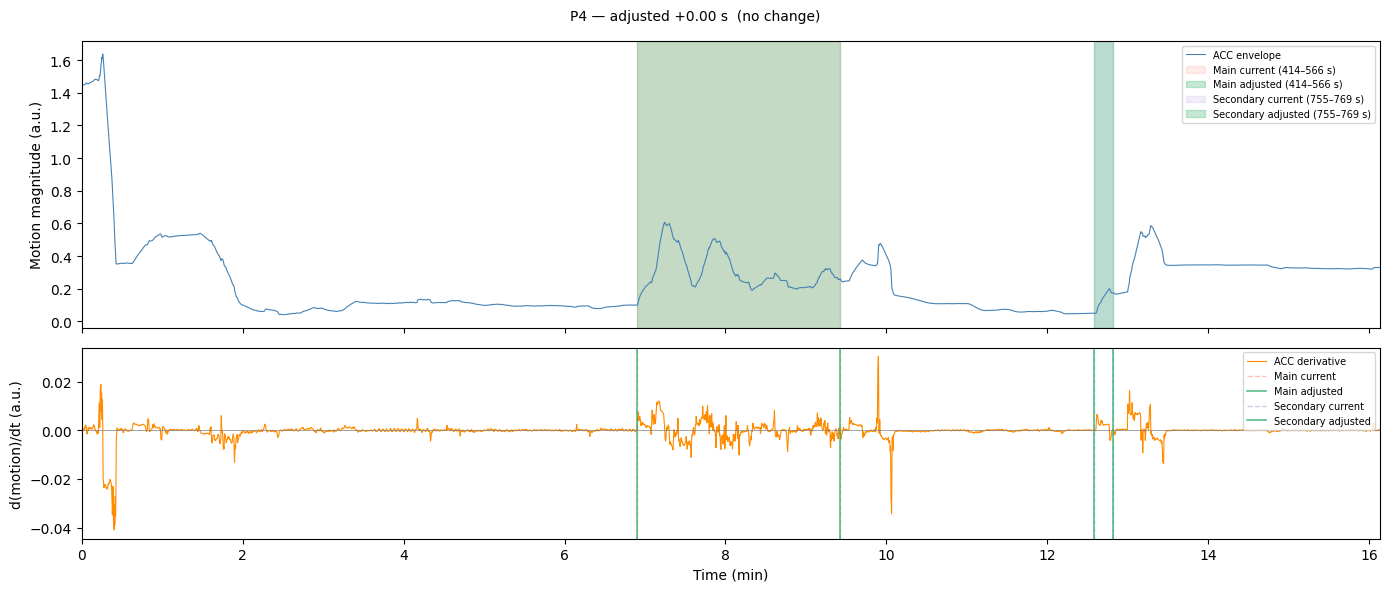

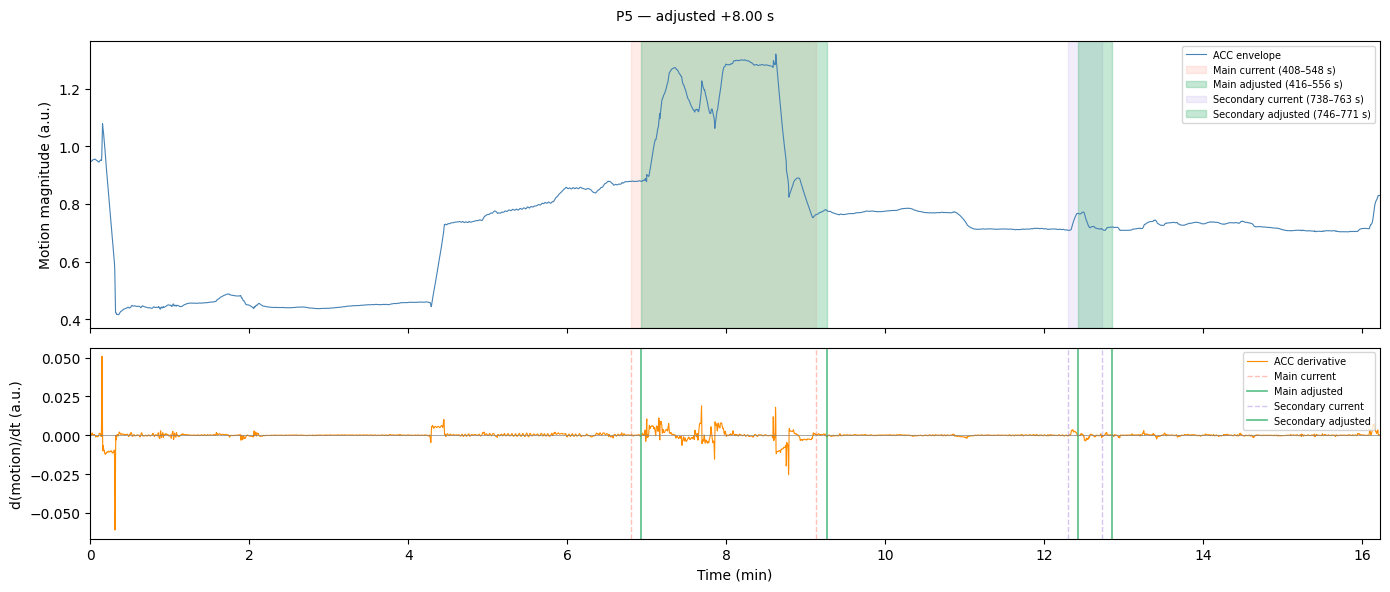

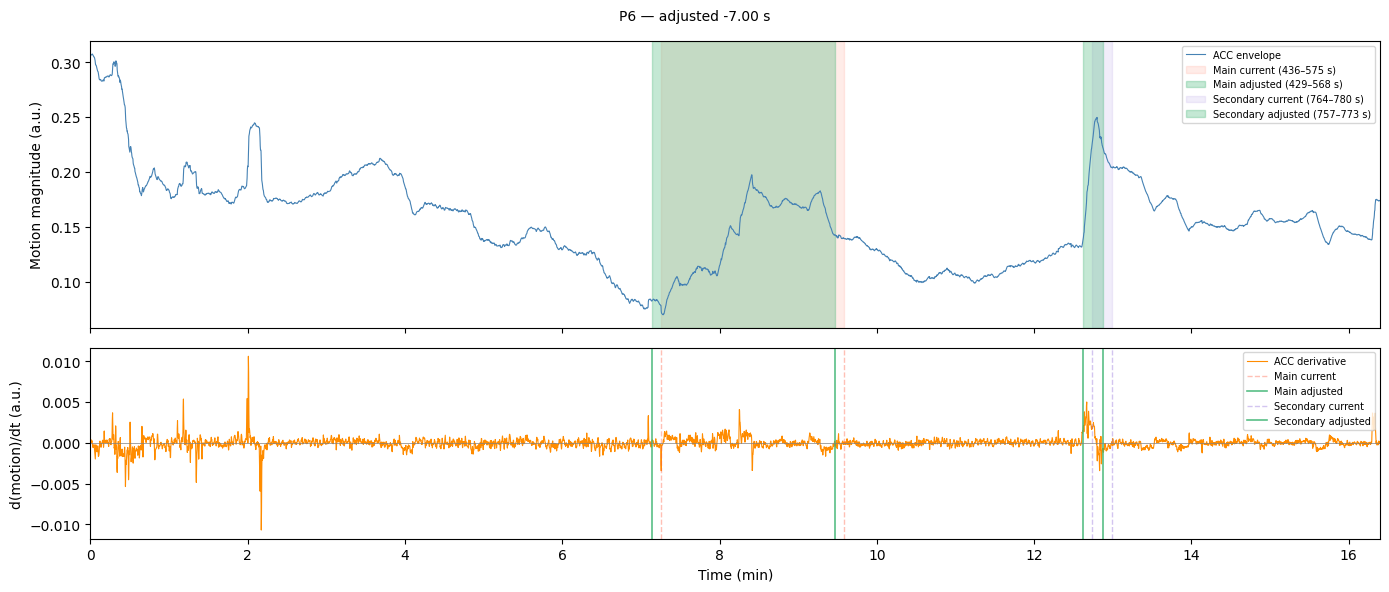

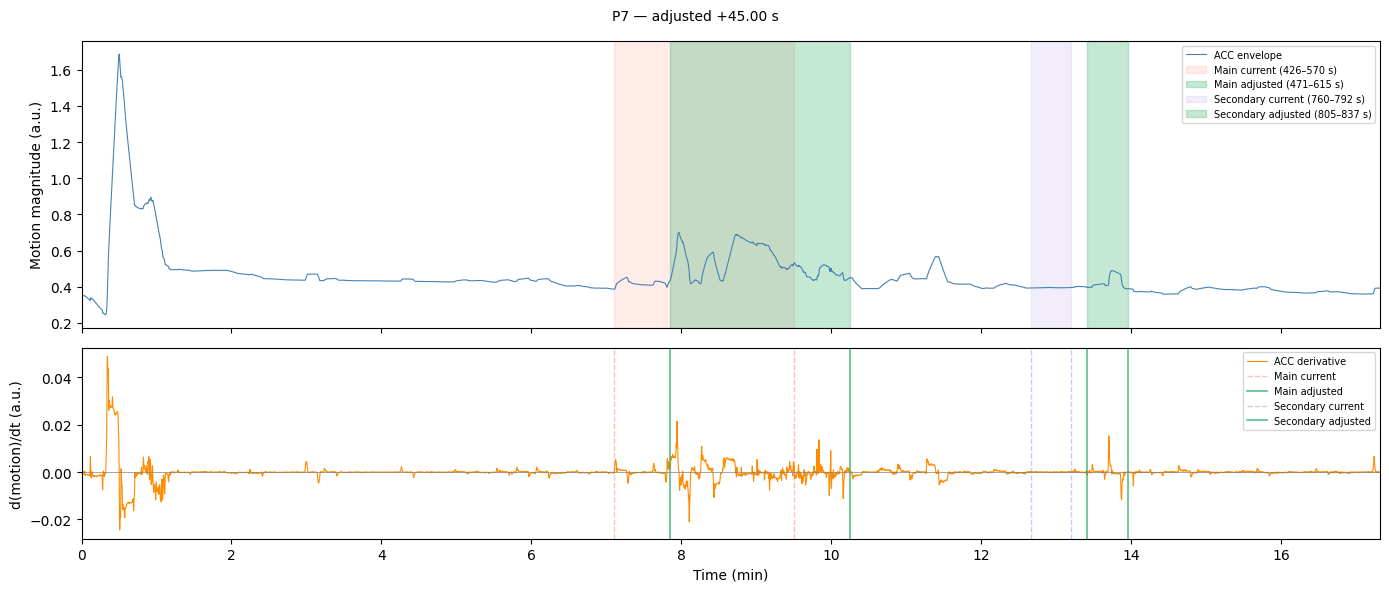

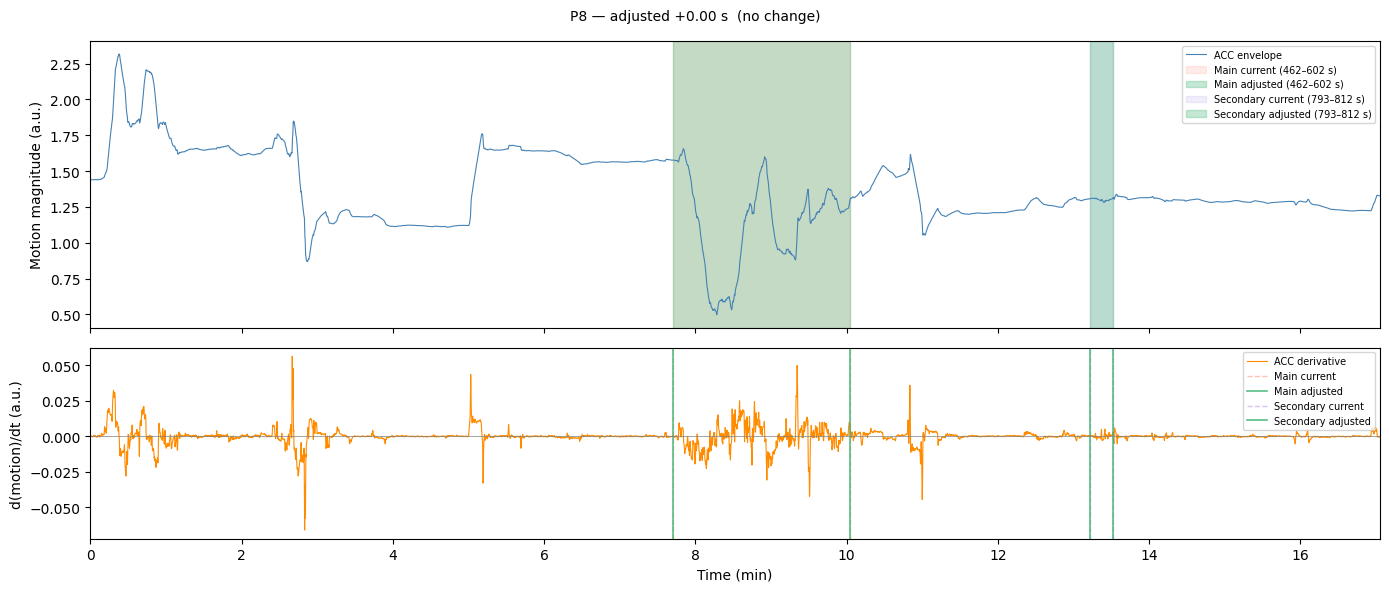

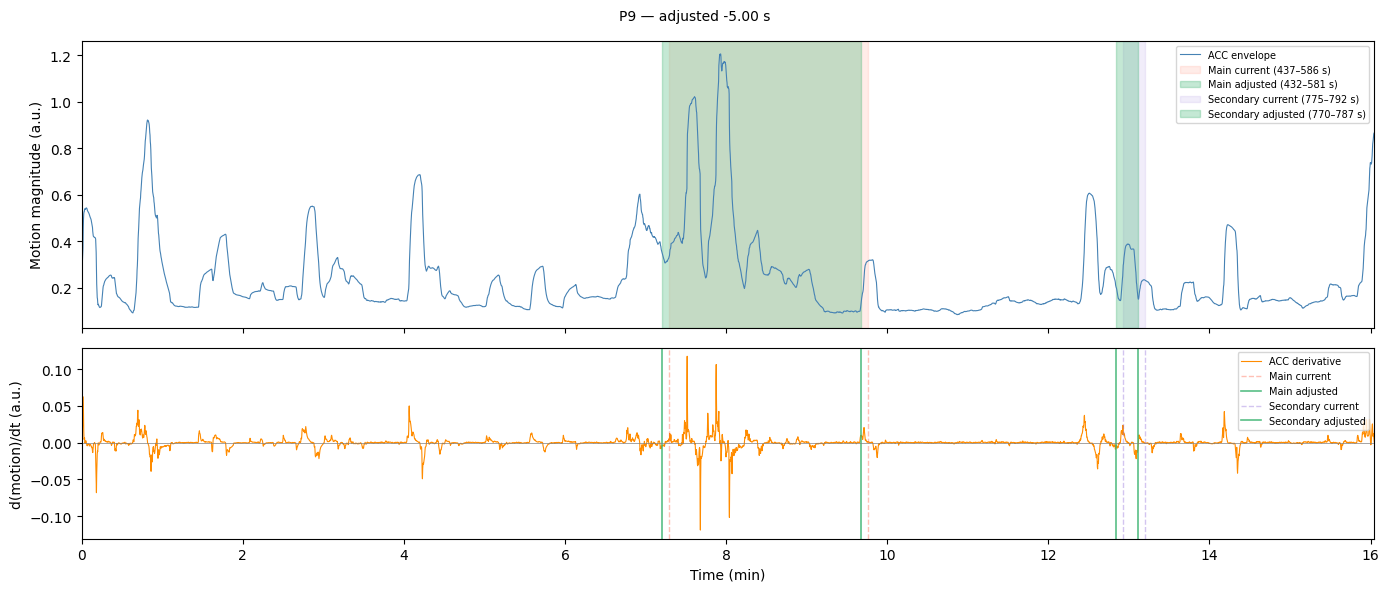

Re-check complete.


In [5]:
for subject in all_subjects:
    if subject not in subject_cache:
        continue

    offset     = manual_offsets.get(subject, 0.0)
    cache      = subject_cache[subject]
    times      = cache['times']
    acc_smooth = cache['acc_smooth']
    acc_deriv  = cache['acc_deriv']
    pause_info = cache['pause_info']

    fig, axes = plt.subplots(
        2, 1, figsize=(14, 6),
        gridspec_kw={'height_ratios': [3, 2]},
    )
    fig.suptitle(
        f'{subject} — adjusted {offset:+.2f} s'
        + ('  (no change)' if offset == 0.0 else ''),
        fontsize=10,
    )
    pause_colors = {'main': 'tomato', 'secondary': 'mediumpurple'}
    _plot_rows(fig, axes, times, acc_smooth, acc_deriv, pause_info,
               pause_colors, offset=offset)
    plt.tight_layout()
    plt.show()

print('Re-check complete.')

## Save offsets

Save to `data/trigger_offsets.csv`

In [6]:
rows = [
    {'subject': subj, 'lag_sec': manual_offsets.get(subj, 0.0)}
    for subj in sorted(subject_cache)
]
df = pd.DataFrame(rows)

csv_path = os.path.join(out_dir, 'trigger_offsets.csv')
df.to_csv(csv_path, index=False)

print(df.to_string(index=False))
print(f'\nsaved → {csv_path}')

subject  lag_sec
     P1      0.0
    P10     13.0
    P11      5.0
    P12      0.0
    P13      0.0
    P14      2.0
    P15      3.0
    P17      0.0
     P2      0.0
     P3      0.0
     P4      0.0
     P5      8.0
     P6     -7.0
     P7     45.0
     P8      0.0
     P9     -5.0

saved → data/trigger_offsets.csv
